# Traditional Fingerprints

In [1]:
#Import everything
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import cftime
import xarray as xr

import cartopy.crs as ccrs
import matplotlib.patches as mpatches
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr
from scipy import stats
from numpy import mean
from numpy import std
from numpy import absolute
from pandas import read_csv
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RepeatedKFold
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
import cartopy.crs as ccrs

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
import cartopy.feature as cfeature
from sklearn.decomposition import PCA
from sklearn import preprocessing

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
import matplotlib.cm as cm
from matplotlib.colors import TwoSlopeNorm
import joblib

In [2]:
def normalise(df_og):
    df=df_og.drop("Model", axis=1)
    mean=df.mean()
    std=df.std()
    normalised_df=(df-mean)/std
    normalised_df["Model"]=df_og["Model"]
    return normalised_df

In [3]:
#Jackson looks at decedal mean of AMOC 26.5 so I will do the same here
def turn_to_df(ds):
    # Convert xarray Dataset to a DataFrame
    df = ds.to_dataframe()
    
    # Reset index and extract 'year' from 'time'
    df = df.reset_index()
    df["year"]=df['time'].apply(lambda x: x.year)

    # Drop unnecessary columns
        
    # Drop duplicates
    df = df.drop_duplicates()
    
    
    return df



In [4]:
def moc_decedal(df):
    # Drop duplicates
    df = df.drop_duplicates()
    
    # Extract the year from the 'time' column
    df["year"] = df['time'].apply(lambda x: x.year)
    
    # Group by decades
    df['decade'] = (df['year'] // 10) * 10  # Calculate the decade for each year
    
    # Determine the column to calculate the mean
    target_col = 'msftyz' if 'msftyz' in df.columns else 'msftmz' if 'msftmz' in df.columns else None
    if not target_col:
        raise ValueError("Neither 'msftyz' nor 'msftmz' columns are present in the DataFrame.")
    
    # Calculate the mean of the target column for each decade
    decadal = df.groupby('decade')[target_col].mean().reset_index()
    
    # Rename columns for clarity
    decadal.columns = ['decade', f'mean_{target_col}']
    
    return decadal


In [5]:
def msftbarot_decedal(df):
    # Identify the columns to drop based on their presence
    columns_to_drop = [col for col in ['lat', 'lon', 'rlat', 'rlon'] if col in df.columns]
    df = df.drop(columns_to_drop, axis=1)
    
    # Initialize an empty list to store the decadal means
    decadal_means = []
    
    # Loop over the DataFrame in chunks of 10
    for i in range(0, len(df), 10):
        chunk = df.iloc[i:i+10]
        mean_value = chunk['min_value'].mean()  # Compute the mean for the 'min_value' in this chunk
        # Append the mean value and the corresponding decade (starting year of the chunk)
        decadal_means.append({
            'decade': chunk['time'].iloc[0],
            'mean_min_value': mean_value * 10**(-9)
        })
    
    # Convert the results into a DataFrame
    decadal_means_df = pd.DataFrame(decadal_means)
    
    return decadal_means_df


### Load all data

In [6]:
#HadGem3_moc=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\moc_HadGem3")
#HadGem3_msftbarot=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\msftbarot_HadGem3")
dipole_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_Dipole_hist.nc")
ceasar_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_Caesar_hist.nc")
spg_HadGem3_hist=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_SPG_hist.nc")

dipole_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_Dipole_pi.nc")
ceasar_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_Caesar_pi.nc")
spg_HadGem3_pi=xr.open_dataset(r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Output_HadGem3_SPG_pi.nc")


In [9]:
dipole_HadGem3_pi["tos"].values

array([[[-16.904453]],

       [[-17.890978]],

       [[-18.083902]],

       ...,

       [[-10.658183]],

       [[-13.079128]],

       [[-15.696825]]], dtype=float32)

In [8]:
CESM2_moc=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\moc_CESM2")
CESM2_msftbarot=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\msftbarot_CESM2")
dipole_CESM2=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_Dipole.nc")
ceasar_CESM2=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_Caesar.nc")
spg_CESM2=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_SPG.nc")

In [9]:
CESM2_moc_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\moc_CESM2")
CESM2_msftbarot_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\msftbarot_CESM2")
dipole_CESM2_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_Dipole_Hist.nc")
ceasar_CESM2_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_Caesar_Hist.nc")
spg_CESM2_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CESM2_SPG_Hist.nc")

In [10]:
MPI_moc=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\moc_MPI")
MPI_msftbarot=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\msftbarot_MPI")
dipole_MPI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_Dipole.nc")
ceasar_MPI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_Caesar.nc")
spg_MPI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_SPG.nc")

C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\coding\times.py:832: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\coding\times.py:832: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\core\indexing.py:560: SerializationWarning: 

In [11]:
MPI_moc_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\moc_MPI")
MPI_msftbarot_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\msftbarot_MPI")
dipole_MPI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_Dipole_Hist.nc")
ceasar_MPI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_Caesar_Hist.nc")
spg_MPI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MPI_SPG_Hist.nc")

In [12]:
MRI_moc=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\moc_MRI")
MRI_msftbarot=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\msftbarot_MRI")
dipole_MRI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_Dipole.nc")
ceasar_MRI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_Caesar.nc")
spg_MRI=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_SPG.nc")

C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\coding\times.py:832: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\coding\times.py:832: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates out of range
  dtype = _decode_cf_datetime_dtype(data, units, calendar, self.use_cftime)
C:\Users\bahar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xarray\core\indexing.py:560: SerializationWarning: 

In [13]:
MRI_moc_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\moc_MRI")
MRI_msftbarot_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\msftbarot_MRI")
dipole_MRI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_Dipole_Hist.nc")
ceasar_MRI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_Caesar_Hist.nc")
spg_MRI_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_MRI_SPG_Hist.nc")

In [14]:
CanESM5_moc=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\moc_CanESM5")
CanESM5_msftbarot=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\msftbarot_CanESM5")
dipole_CanESM5=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_Dipole.nc")
ceasar_CanESM5=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_Caesar.nc")
spg_CanESM5=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_SPG.nc")

In [15]:
CanESM5_moc_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\moc_CanESM5")
CanESM5_msftbarot_hist=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\Historical\msftbarot_CanESM5")
dipole_CanESM5_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_Dipole_Hist.nc")
ceasar_CanESM5_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_Caesar_Hist.nc")
spg_CanESM5_hist=xr.open_dataset(r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\Fingerprints\Output_CanESM5_SPG_Hist.nc")

### Process mocs and msftbarots

In [16]:
HadGem3_decedal_moc=moc_decedal(HadGem3_moc)
CESM2_decedal_moc=moc_decedal(CESM2_moc)
CanESM5_decedal_moc=moc_decedal(CanESM5_moc)
MPI_decedal_moc=moc_decedal(MPI_moc)
MRI_decedal_moc=moc_decedal(MRI_moc)

HadGem3_decedal_moc_hist=moc_decedal(HadGem3_moc_hist)
CESM2_decedal_moc_hist=moc_decedal(CESM2_moc_hist)
CanESM5_decedal_moc_hist=moc_decedal(CanESM5_moc_hist)
MPI_decedal_moc_hist=moc_decedal(MPI_moc_hist)
MRI_decedal_moc_hist=moc_decedal(MRI_moc_hist)

C:\Users\bahar\AppData\Local\Temp\ipykernel_13020\986836641.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["year"] = df['time'].apply(lambda x: x.year)
C:\Users\bahar\AppData\Local\Temp\ipykernel_13020\986836641.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['decade'] = (df['year'] // 10) * 10  # Calculate the decade for each year
C:\Users\bahar\AppData\Local\Temp\ipykernel_13020\986836641.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try u

In [17]:
HadGem3_decedal_msftbarot=msftbarot_decedal(HadGem3_msftbarot)
CESM2_decedal_msftbarot=msftbarot_decedal(CESM2_msftbarot)
#CanESM5_decedal_msftbarot=msftbarot_decedal(CanESM5_msftbarot)
MPI_decedal_msftbarot=msftbarot_decedal(MPI_msftbarot)
MRI_decedal_msftbarot=msftbarot_decedal(MRI_msftbarot)

HadGem3_decedal_msftbarot_hist=msftbarot_decedal(HadGem3_msftbarot_hist)
CESM2_decedal_msftbarot_hist=msftbarot_decedal(CESM2_msftbarot_hist)
CanESM5_decedal_msftbarot_hist=msftbarot_decedal(CanESM5_msftbarot_hist)
MPI_decedal_msftbarot_hist=msftbarot_decedal(MPI_msftbarot_hist)
MRI_decedal_msftbarot_hist=msftbarot_decedal(MRI_msftbarot_hist)

In [18]:
decadal_means = []
df=CanESM5_msftbarot
# Loop over the DataFrame in chunks of 10
for i in range(0, len(df), 10):
    chunk = df.iloc[i:i+10]
    mean_value = chunk['min_value'].mean()  # Compute the mean for the 'min_value' in this chunk
    # Append the mean value and the corresponding decade (starting year of the chunk)
    decadal_means.append({
        'mean_min_value': mean_value * 10**(-9)
    })

# Convert the results into a DataFrame
decadal_means_df = pd.DataFrame(decadal_means)

CanESM5_decedal_msftbarot=decadal_means_df

# DIPOLE

    Getting annual averages

In [34]:
# dipole_CESM2_annual=dipole_CESM2["tos"].resample(time="1Y").mean(dim="time")
# dipole_CanESM5_annual=dipole_CanESM5["tos"].resample(time="1Y").mean(dim="time")
# dipole_MPI_annual=dipole_MPI["tos"].resample(time="1Y").mean(dim="time")
# dipole_MRI_annual=dipole_MRI["tos"].resample(time="1Y").mean(dim="time")
dipole_HadGem3_annual=dipole_HadGem3_pi["tos"].resample(time="1Y").mean(dim="time")

# dipole_CESM2_hist_annual=dipole_CESM2_hist["tos"].resample(time="1Y").mean(dim="time")
# dipole_CanESM5_hist_annual=dipole_CanESM5_hist["tos"].resample(time="1Y").mean(dim="time")
# dipole_MPI_hist_annual=dipole_MPI_hist["tos"].resample(time="1Y").mean(dim="time")
# dipole_MRI_hist_annual=dipole_MRI_hist["tos"].resample(time="1Y").mean(dim="time")
dipole_HadGem3_hist_annual=dipole_HadGem3_hist["tos"].resample(time="1Y").mean(dim="time")

In [35]:
dipole_HadGem3_hist_annual

<xarray.DataArray 'tos' (time: 165, lat: 1, lon: 1)>
array([[[-13.7020035]],

       [[-14.136281 ]],

       [[-13.870731 ]],

       [[-13.964732 ]],

       [[-14.117279 ]],

       [[-14.146294 ]],

       [[-14.239696 ]],

       [[-13.492092 ]],

       [[-13.43135  ]],

       [[-13.507392 ]],

...

       [[-14.119742 ]],

       [[-13.897167 ]],

       [[-13.983392 ]],

       [[-13.972431 ]],

       [[-14.530129 ]],

       [[-14.039504 ]],

       [[-14.361557 ]],

       [[-13.938599 ]],

       [[-14.010097 ]],

       [[-13.854865 ]]], dtype=float32)
Coordinates:
  * lon      (lon) float64 0.0
  * lat      (lat) float64 0.0
  * time     (time) object 1850-12-30 00:00:00 ... 2014-12-30 00:00:00
Attributes:
    standard_name:  sea_surface_temperature
    long_name:      Sea Surface Temperature
    units:          degC
    comment:        Temperature of upper boundary of the liquid ocean, includ...
    original_name:  mo: (variable_name: tos)
    cell_methods:   area: mean where sea time: mean
    cell_measures:  area: areacello

In [36]:
dipole_HadGem3_df_annual=turn_to_df(dipole_HadGem3_annual)
# dipole_CESM2_df_annual=turn_to_df(dipole_CESM2_annual)
# dipole_CanESM5_df_annual=turn_to_df(dipole_CanESM5_annual)
# dipole_MPI_df_annual=turn_to_df(dipole_MPI_annual)
# dipole_MRI_df_annual=turn_to_df(dipole_MRI_annual)

dipole_HadGem3_df_hist_annual=turn_to_df(dipole_HadGem3_hist_annual)
# dipole_CESM2_df_hist_annual=turn_to_df(dipole_CESM2_hist_annual)
# dipole_CanESM5_df_hist_annual=turn_to_df(dipole_CanESM5_hist_annual)
# dipole_MPI_df_hist_annual=turn_to_df(dipole_MPI_hist_annual)
# dipole_MRI_df_hist_annual=turn_to_df(dipole_MRI_hist_annual)

In [37]:
# Dump all dfs to be used in Figures for Annual Fingerprint Ranking Paper

joblib.dump(dipole_HadGem3_df_annual, r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_HadGem3_df_annual")
# joblib.dump(dipole_CESM2_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CESM2_df_annual")
# joblib.dump(dipole_CanESM5_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CanESM5_df_annual")
# joblib.dump(dipole_MPI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MPI_df_annual")
# joblib.dump(dipole_MRI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MRI_df_annual")
joblib.dump(dipole_HadGem3_df_hist_annual, r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_HadGem3_df_hist_annual")
# joblib.dump(dipole_CESM2_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CESM2_df_hist_annual")
# joblib.dump(dipole_CanESM5_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CanESM5_df_hist_annual")
# joblib.dump(dipole_MPI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MPI_df_hist_annual")
# joblib.dump(dipole_MRI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MRI_df_hist_annual")

['/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/dipole_HadGem3_df_hist_annual']

    Getting Decadal Averages

In [23]:
dipole_CESM2=dipole_CESM2["tos"].resample(time="10Y").mean(dim="time")
dipole_CanESM5=dipole_CanESM5["tos"].resample(time="10Y").mean(dim="time")
dipole_MPI=dipole_MPI["tos"].resample(time="10Y").mean(dim="time")
dipole_MRI=dipole_MRI["tos"].resample(time="10Y").mean(dim="time")
dipole_HadGem3=dipole_HadGem3["tos"].resample(time="10Y").mean(dim="time")

dipole_CESM2_hist=dipole_CESM2_hist["tos"].resample(time="10Y").mean(dim="time")
dipole_CanESM5_hist=dipole_CanESM5_hist["tos"].resample(time="10Y").mean(dim="time")
dipole_MPI_hist=dipole_MPI_hist["tos"].resample(time="10Y").mean(dim="time")
dipole_MRI_hist=dipole_MRI_hist["tos"].resample(time="10Y").mean(dim="time")
dipole_HadGem3_hist=dipole_HadGem3_hist["tos"].resample(time="10Y").mean(dim="time")

In [24]:
dipole_HadGem3_df=turn_to_df(dipole_HadGem3)
dipole_CESM2_df=turn_to_df(dipole_CESM2)
dipole_CanESM5_df=turn_to_df(dipole_CanESM5)
dipole_MPI_df=turn_to_df(dipole_MPI)
dipole_MRI_df=turn_to_df(dipole_MRI)

dipole_HadGem3_df_hist=turn_to_df(dipole_HadGem3_hist)
dipole_CESM2_df_hist=turn_to_df(dipole_CESM2_hist)
dipole_CanESM5_df_hist=turn_to_df(dipole_CanESM5_hist)
dipole_MPI_df_hist=turn_to_df(dipole_MPI_hist)
dipole_MRI_df_hist=turn_to_df(dipole_MRI_hist)

In [25]:
# Dump all dfs to be used in Figures for Fingerprint Ranking Paper - copy

joblib.dump(dipole_HadGem3_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_HadGem3_df")
joblib.dump(dipole_CESM2_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CESM2_df")
joblib.dump(dipole_CanESM5_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CanESM5_df")
joblib.dump(dipole_MPI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MPI_df")
joblib.dump(dipole_MRI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MRI_df")

joblib.dump(dipole_HadGem3_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_HadGem3_df_hist")
joblib.dump(dipole_CESM2_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CESM2_df_hist")
joblib.dump(dipole_CanESM5_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_CanESM5_df_hist")
joblib.dump(dipole_MPI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MPI_df_hist")
joblib.dump(dipole_MRI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\dipole_MRI_df_hist")

['C:\\TUM Study\\Thesis\\Thesis Code\\AMOC_SPG_Code\\clean_dfs\\dipole_MRI_df_hist']

# SST_ceasar

In [38]:
# ceasar_CESM2_annual=ceasar_CESM2["tos"].resample(time="1Y").mean(dim="time")
# ceasar_CanESM5_annual=ceasar_CanESM5["tos"].resample(time="1Y").mean(dim="time")
# ceasar_MPI_annual=ceasar_MPI["tos"].resample(time="1Y").mean(dim="time")
# ceasar_MRI_annual=ceasar_MRI["tos"].resample(time="1Y").mean(dim="time")
ceasar_HadGem3_annual=ceasar_HadGem3_pi["tos"].resample(time="1Y").mean(dim="time")

# ceasar_CESM2_hist_annual=ceasar_CESM2_hist["tos"].resample(time="1Y").mean(dim="time")
# ceasar_CanESM5_hist_annual=ceasar_CanESM5_hist["tos"].resample(time="1Y").mean(dim="time")
# ceasar_MPI_hist_annual=ceasar_MPI_hist["tos"].resample(time="1Y").mean(dim="time")
# ceasar_MRI_hist_annual=ceasar_MRI_hist["tos"].resample(time="1Y").mean(dim="time")
ceasar_HadGem3_hist_annual=ceasar_HadGem3_hist["tos"].resample(time="1Y").mean(dim="time")

In [39]:
ceasar_HadGem3_df_annual=turn_to_df(ceasar_HadGem3_annual)
# ceasar_CESM2_df_annual=turn_to_df(ceasar_CESM2_annual)
# ceasar_CanESM5_df_annual=turn_to_df(ceasar_CanESM5_annual)
# ceasar_MPI_df_annual=turn_to_df(ceasar_MPI_annual)
# ceasar_MRI_df_annual=turn_to_df(ceasar_MRI_annual)

ceasar_HadGem3_df_hist_annual=turn_to_df(ceasar_HadGem3_hist_annual)
# ceasar_CESM2_df_hist_annual=turn_to_df(ceasar_CESM2_hist_annual)
# ceasar_CanESM5_df_hist_annual=turn_to_df(ceasar_CanESM5_hist_annual)
# ceasar_MPI_df_hist_annual=turn_to_df(ceasar_MPI_hist_annual)
# ceasar_MRI_df_hist_annual=turn_to_df(ceasar_MRI_hist_annual)

In [40]:
# Dump all dfs to be used in Figures for Annual Fingerprint Ranking Paper

joblib.dump(ceasar_HadGem3_df_annual, r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_HadGem3_df_annual")
# joblib.dump(ceasar_CESM2_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CESM2_df_annual")
# joblib.dump(ceasar_CanESM5_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CanESM5_df_annual")
# joblib.dump(ceasar_MPI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MPI_df_annual")
# joblib.dump(ceasar_MRI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MRI_df_annual")

joblib.dump(ceasar_HadGem3_df_hist_annual,r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_HadGem3_df_hist_annual")
# joblib.dump(ceasar_CESM2_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CESM2_df_hist_annual")
# joblib.dump(ceasar_CanESM5_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CanESM5_df_hist_annual")
# joblib.dump(ceasar_MPI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MPI_df_hist_annual")
# joblib.dump(ceasar_MRI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MRI_df_hist_annual")

['/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/ceasar_HadGem3_df_hist_annual']

In [41]:
ceasar_HadGem3_df_hist_annual

,time,lat,lon,tos,year
0,1850-12-30 00:00:00,0.0,0.0,-11.773418,1850
1,1851-12-30 00:00:00,0.0,0.0,-12.539612,1851
2,1852-12-30 00:00:00,0.0,0.0,-12.753138,1852
3,1853-12-30 00:00:00,0.0,0.0,-12.670925,1853
4,1854-12-30 00:00:00,0.0,0.0,-12.630157,1854
...,...,...,...,...,...
160,2010-12-30 00:00:00,0.0,0.0,-12.359520,2010
161,2011-12-30 00:00:00,0.0,0.0,-12.713305,2011
162,2012-12-30 00:00:00,0.0,0.0,-11.959513,2012
163,2013-12-30 00:00:00,0.0,0.0,-11.969151,2013


    Decadal

In [29]:
ceasar_CESM2=ceasar_CESM2["tos"].resample(time="10Y").mean(dim="time")
ceasar_CanESM5=ceasar_CanESM5["tos"].resample(time="10Y").mean(dim="time")
ceasar_MPI=ceasar_MPI["tos"].resample(time="10Y").mean(dim="time")
ceasar_MRI=ceasar_MRI["tos"].resample(time="10Y").mean(dim="time")
ceasar_HadGem3=ceasar_HadGem3["tos"].resample(time="10Y").mean(dim="time")

ceasar_CESM2_hist=ceasar_CESM2_hist["tos"].resample(time="10Y").mean(dim="time")
ceasar_CanESM5_hist=ceasar_CanESM5_hist["tos"].resample(time="10Y").mean(dim="time")
ceasar_MPI_hist=ceasar_MPI_hist["tos"].resample(time="10Y").mean(dim="time")
ceasar_MRI_hist=ceasar_MRI_hist["tos"].resample(time="10Y").mean(dim="time")
ceasar_HadGem3_hist=ceasar_HadGem3_hist["tos"].resample(time="10Y").mean(dim="time")

In [30]:
ceasar_HadGem3_df=turn_to_df(ceasar_HadGem3)
ceasar_CESM2_df=turn_to_df(ceasar_CESM2)
ceasar_CanESM5_df=turn_to_df(ceasar_CanESM5)
ceasar_MPI_df=turn_to_df(ceasar_MPI)
ceasar_MRI_df=turn_to_df(ceasar_MRI)

ceasar_HadGem3_df_hist=turn_to_df(ceasar_HadGem3_hist)
ceasar_CESM2_df_hist=turn_to_df(ceasar_CESM2_hist)
ceasar_CanESM5_df_hist=turn_to_df(ceasar_CanESM5_hist)
ceasar_MPI_df_hist=turn_to_df(ceasar_MPI_hist)
ceasar_MRI_df_hist=turn_to_df(ceasar_MRI_hist)

In [31]:
# Dump all dfs to be used in Figures for Fingerprint Ranking Paper - copy

joblib.dump(ceasar_HadGem3_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_HadGem3_df")
joblib.dump(ceasar_CESM2_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CESM2_df")
joblib.dump(ceasar_CanESM5_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CanESM5_df")
joblib.dump(ceasar_MPI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MPI_df")
joblib.dump(ceasar_MRI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MRI_df")

joblib.dump(ceasar_HadGem3_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_HadGem3_df_hist")
joblib.dump(ceasar_CESM2_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CESM2_df_hist")
joblib.dump(ceasar_CanESM5_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_CanESM5_df_hist")
joblib.dump(ceasar_MPI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MPI_df_hist")
joblib.dump(ceasar_MRI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\ceasar_MRI_df_hist")

['C:\\TUM Study\\Thesis\\Thesis Code\\AMOC_SPG_Code\\clean_dfs\\ceasar_MRI_df_hist']

# SST_spg

In [42]:
# spg_CESM2_annual=spg_CESM2["tos"].resample(time="1Y").mean(dim="time")
# spg_CanESM5_annual=spg_CanESM5["tos"].resample(time="1Y").mean(dim="time")
# spg_MPI_annual=spg_MPI["tos"].resample(time="1Y").mean(dim="time")
# spg_MRI_annual=spg_MRI["tos"].resample(time="1Y").mean(dim="time")
spg_HadGem3_annual=spg_HadGem3_pi["tos"].resample(time="1Y").mean(dim="time")

# spg_CESM2_hist_annual=spg_CESM2_hist["tos"].resample(time="1Y").mean(dim="time")
# spg_CanESM5_hist_annual=spg_CanESM5_hist["tos"].resample(time="1Y").mean(dim="time")
# spg_MPI_hist_annual=spg_MPI_hist["tos"].resample(time="1Y").mean(dim="time")
# spg_MRI_hist_annual=spg_MRI_hist["tos"].resample(time="1Y").mean(dim="time")
spg_HadGem3_hist_annual=spg_HadGem3_hist["tos"].resample(time="1Y").mean(dim="time")

In [43]:
spg_HadGem3_df_annual=turn_to_df(spg_HadGem3_annual)
# spg_CESM2_df_annual=turn_to_df(spg_CESM2_annual)
# spg_CanESM5_df_annual=turn_to_df(spg_CanESM5_annual)
# spg_MPI_df_annual=turn_to_df(spg_MPI_annual)
# spg_MRI_df_annual=turn_to_df(spg_MRI_annual)

spg_HadGem3_df_hist_annual=turn_to_df(spg_HadGem3_hist_annual)
# spg_CESM2_df_hist_annual=turn_to_df(spg_CESM2_hist_annual)
# spg_CanESM5_df_hist_annual=turn_to_df(spg_CanESM5_hist_annual)
# spg_MPI_df_hist_annual=turn_to_df(spg_MPI_hist_annual)
# spg_MRI_df_hist_annual=turn_to_df(spg_MRI_hist_annual)

In [44]:
# Dump all dfs to be used in Figures for Fingerprint Ranking Paper - copy

joblib.dump(spg_HadGem3_df_annual,r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_HadGem3_df_annual")
# joblib.dump(spg_CESM2_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CESM2_df_annual")
# joblib.dump(spg_CanESM5_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CanESM5_df_annual")
# joblib.dump(spg_MPI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MPI_df_annual")
# joblib.dump(spg_MRI_df_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MRI_df_annual")

joblib.dump(spg_HadGem3_df_hist_annual, r"/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_HadGem3_df_hist_annual")
# joblib.dump(spg_CESM2_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CESM2_df_hist_annual")
# joblib.dump(spg_CanESM5_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CanESM5_df_hist_annual")
# joblib.dump(spg_MPI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MPI_df_hist_annual")
# joblib.dump(spg_MRI_df_hist_annual, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MRI_df_hist_annual")

['/p/tmp/baharem/August_25/Statistically_Optimal_Fingerprints/Data/clean_dfs/spg_HadGem3_df_hist_annual']

In [45]:
spg_HadGem3_df_hist_annual

,time,lat,lon,tos,year
0,1850-12-30 00:00:00,0.0,0.0,-11.716733,1850
1,1851-12-30 00:00:00,0.0,0.0,-12.479583,1851
2,1852-12-30 00:00:00,0.0,0.0,-12.693953,1852
3,1853-12-30 00:00:00,0.0,0.0,-12.727180,1853
4,1854-12-30 00:00:00,0.0,0.0,-12.814175,1854
...,...,...,...,...,...
160,2010-12-30 00:00:00,0.0,0.0,-12.073941,2010
161,2011-12-30 00:00:00,0.0,0.0,-12.428394,2011
162,2012-12-30 00:00:00,0.0,0.0,-11.692490,2012
163,2013-12-30 00:00:00,0.0,0.0,-11.820996,2013


    Decadal

In [35]:
spg_CESM2=spg_CESM2["tos"].resample(time="10Y").mean(dim="time")
spg_CanESM5=spg_CanESM5["tos"].resample(time="10Y").mean(dim="time")
spg_MPI=spg_MPI["tos"].resample(time="10Y").mean(dim="time")
spg_MRI=spg_MRI["tos"].resample(time="10Y").mean(dim="time")
spg_HadGem3=spg_HadGem3["tos"].resample(time="10Y").mean(dim="time")

spg_CESM2_hist=spg_CESM2_hist["tos"].resample(time="10Y").mean(dim="time")
spg_CanESM5_hist=spg_CanESM5_hist["tos"].resample(time="10Y").mean(dim="time")
spg_MPI_hist=spg_MPI_hist["tos"].resample(time="10Y").mean(dim="time")
spg_MRI_hist=spg_MRI_hist["tos"].resample(time="10Y").mean(dim="time")
spg_HadGem3_hist=spg_HadGem3_hist["tos"].resample(time="10Y").mean(dim="time")

In [36]:
spg_HadGem3_df=turn_to_df(spg_HadGem3)
spg_CESM2_df=turn_to_df(spg_CESM2)
spg_CanESM5_df=turn_to_df(spg_CanESM5)
spg_MPI_df=turn_to_df(spg_MPI)
spg_MRI_df=turn_to_df(spg_MRI)

spg_HadGem3_df_hist=turn_to_df(spg_HadGem3_hist)
spg_CESM2_df_hist=turn_to_df(spg_CESM2_hist)
spg_CanESM5_df_hist=turn_to_df(spg_CanESM5_hist)
spg_MPI_df_hist=turn_to_df(spg_MPI_hist)
spg_MRI_df_hist=turn_to_df(spg_MRI_hist)

In [37]:
joblib.dump(spg_HadGem3_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_HadGem3_df")
joblib.dump(spg_CESM2_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CESM2_df")
joblib.dump(spg_CanESM5_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CanESM5_df")
joblib.dump(spg_MPI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MPI_df")
joblib.dump(spg_MRI_df, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MRI_df")

joblib.dump(spg_HadGem3_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_HadGem3_df_hist")
joblib.dump(spg_CESM2_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CESM2_df_hist")
joblib.dump(spg_CanESM5_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_CanESM5_df_hist")
joblib.dump(spg_MPI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MPI_df_hist")
joblib.dump(spg_MRI_df_hist, r"C:\TUM Study\Thesis\Thesis Code\AMOC_SPG_Code\clean_dfs\spg_MRI_df_hist")

['C:\\TUM Study\\Thesis\\Thesis Code\\AMOC_SPG_Code\\clean_dfs\\spg_MRI_df_hist']

# Comparison with MOC and MSFTBAROT

In [38]:
ceasar_HadGem3_df=ceasar_HadGem3_df[:100]
dipole_HadGem3_df=dipole_HadGem3_df[:100]
spg_HadGem3_df=spg_HadGem3_df[:100]
HadGem3_decedal_moc=HadGem3_decedal_moc[:100]
HadGem3_decedal_msftbarot=HadGem3_decedal_msftbarot[:100]


In [39]:
ceasar_MPI_df=ceasar_MPI_df[:100]
dipole_MPI_df=dipole_MPI_df[:100]
spg_MPI_df=spg_MPI_df[:100]
MPI_decedal_moc=MPI_decedal_moc[:100]
MPI_decedal_msftbarot=MPI_decedal_msftbarot[:100]

In [40]:
ceasar_CESM2_df=ceasar_CESM2_df[:120]
dipole_CESM2_df=dipole_CESM2_df[:120]
spg_CESM2_df=spg_CESM2_df[:120]
CESM2_decedal_moc=CESM2_decedal_moc[:120]
CESM2_decedal_msftbarot=CESM2_decedal_msftbarot[:120]

In [41]:
ceasar_CanESM5_df=ceasar_CanESM5_df[:100]
dipole_CanESM5_df=dipole_CanESM5_df[:100]
spg_CanESM5_df=spg_CanESM5_df[:100]
CanESM5_decedal_moc=CanESM5_decedal_moc[:100]
CanESM5_decedal_msftbarot=CanESM5_decedal_msftbarot[:100]

In [42]:
#THESE ARE ANNUAL (5year rolling) SHOULD NOT BE ON THE 2D GRAPH
MOC_piControl_results=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\MOC_piControl_results")
SPG_piControl_results=joblib.load(r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\SPG_piControl_results")
MOC_historical_results=joblib.load( r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\MOC_historical_results")
SPG_historical_results=joblib.load( r"C:\TUM Study\Thesis\Thesis Code\Datasets\New_Data_October\Processed Files\SPG_historical_results")

In [43]:
# List of all models
all_models = ["HadGem3", "CESM2", "CanESM5", "MPI", "MRI"]

# List to store correlation coefficients
corr_coefs = []

# Loop through each model
for model in all_models:
    # Generate variable names based on the naming convention
    decedal_moc_name = f"{model}_decedal_moc"  # e.g., "HadGem3_decedal_moc"
    ceasar_df_name = f"ceasar_{model}_df"      # e.g., "ceasar_HadGem3_df"
    dipole_df_name = f"dipole_{model}_df"      # e.g., "dipole_HadGem3_df"
    spg_df_name = f"spg_{model}_df"            # e.g., "spg_HadGem3_df"

    # Access the variables
    decedal_moc = globals().get(decedal_moc_name)
    ceasar_df = globals().get(ceasar_df_name)
    dipole_df = globals().get(dipole_df_name)
    spg_df = globals().get(spg_df_name)

    # Determine whether to use 'mean_msftyz' or 'mean_msftmz'
    if "mean_msftyz" in decedal_moc.columns:
        decedal_moc_vals = decedal_moc["mean_msftyz"].values
    elif "mean_msftmz" in decedal_moc.columns:
        decedal_moc_vals = decedal_moc["mean_msftmz"].values
    else:
        print(f"Skipping {model}: Neither 'mean_msftyz' nor 'mean_msftmz' found in {decedal_moc_name}")
        continue

    # Extract relevant columns
    ceasar_vals = ceasar_df["tos"].values
    dipole_vals = dipole_df["tos"].values
    spg_vals = spg_df["tos"].values

    # Calculate correlation coefficients
    ceasar_corr_coef = np.corrcoef(ceasar_vals, decedal_moc_vals)[0, 1]
    dipole_corr_coef = np.corrcoef(dipole_vals, decedal_moc_vals)[0, 1]
    spg_corr_coef = np.corrcoef(spg_vals, decedal_moc_vals)[0, 1]
    ridge_corr_coef=MOC_piControl_results[model]["Correlation"].iloc[:1].values

    # Store the result
    corr_coefs.append({
        'model': model,
        'ceasar_corr': ceasar_corr_coef,
        'dipole_corr': dipole_corr_coef,
        'spg_corr': spg_corr_coef, 
        "ridge_corr": ridge_corr_coef
    })

# Convert results to a DataFrame
corr_coefs_df = pd.DataFrame(corr_coefs)
moc_corrs=corr_coefs_df
moc_corrs


,model,ceasar_corr,dipole_corr,spg_corr,ridge_corr
0,HadGem3,0.235101,0.476173,0.157332,[0.7581734720488016]
1,CESM2,0.345547,0.403292,0.389913,[0.8570851088668829]
2,CanESM5,0.199205,0.070806,0.151614,[0.8466069130493223]
3,MPI,-0.222753,-0.113846,-0.206401,[0.8023740252100668]
4,MRI,-0.023410,0.243909,0.044369,[0.8615973437269552]


In [44]:
# List of all models
all_models = ["HadGem3", "CESM2", "CanESM5", "MPI", "MRI"]

# List to store correlation coefficients
corr_coefs = []

# Loop through each model
for model in all_models:
    # Generate variable names based on the naming convention
    decedal_msftbarot_name = f"{model}_decedal_msftbarot"  # e.g., "HadGem3_decedal_moc"
    ceasar_df_name = f"ceasar_{model}_df"      # e.g., "ceasar_HadGem3_df"
    dipole_df_name = f"dipole_{model}_df"      # e.g., "dipole_HadGem3_df"
    spg_df_name = f"spg_{model}_df"            # e.g., "spg_HadGem3_df"

    # Access the variables
    decedal_msftbarot = globals().get(decedal_msftbarot_name)
    ceasar_df = globals().get(ceasar_df_name)
    dipole_df = globals().get(dipole_df_name)
    spg_df = globals().get(spg_df_name)

    
   
    decedal_msftbarot_vals = decedal_msftbarot["mean_min_value"].values


    # Extract relevant columns
    ceasar_vals = ceasar_df["tos"].values
    dipole_vals = dipole_df["tos"].values
    spg_vals = spg_df["tos"].values

    # Calculate correlation coefficients
    ceasar_corr_coef = np.corrcoef(ceasar_vals, decedal_msftbarot_vals)[0, 1]
    dipole_corr_coef = np.corrcoef(dipole_vals, decedal_msftbarot_vals)[0, 1]
    spg_corr_coef = np.corrcoef(spg_vals, decedal_msftbarot_vals)[0, 1]
    ridge_corr_coef=SPG_piControl_results[model]["Correlation"].iloc[:1].values

    # Store the result
    corr_coefs.append({
        'model': model,
        'ceasar_corr': ceasar_corr_coef,
        'dipole_corr': dipole_corr_coef,
        'spg_corr': spg_corr_coef, 
        "ridge_corr": ridge_corr_coef
    })

# Convert results to a DataFrame
corr_coefs_df = pd.DataFrame(corr_coefs)
msftbarot_corrs=corr_coefs_df
msftbarot_corrs

,model,ceasar_corr,dipole_corr,spg_corr,ridge_corr
0,HadGem3,0.094242,0.140473,-0.093915,[0.933949102603998]
1,CESM2,0.262656,0.224338,0.227481,[0.8011310983095183]
2,CanESM5,0.029754,-0.002953,0.006877,[0.9777544624258739]
3,MPI,0.328831,0.384791,0.364141,[0.5865625408476302]
4,MRI,0.159699,0.226302,0.177972,[0.4253759030519378]


In [45]:
moc_corrs

,model,ceasar_corr,dipole_corr,spg_corr,ridge_corr
0,HadGem3,0.235101,0.476173,0.157332,[0.7581734720488016]
1,CESM2,0.345547,0.403292,0.389913,[0.8570851088668829]
2,CanESM5,0.199205,0.070806,0.151614,[0.8466069130493223]
3,MPI,-0.222753,-0.113846,-0.206401,[0.8023740252100668]
4,MRI,-0.023410,0.243909,0.044369,[0.8615973437269552]


# Plotting the 2D graph

In [46]:
# Loop through each model and compute the correlation
moc_fingerprint_spg_corr = {}

for model in all_models:
    spg_value = SPG_piControl_results[model]["True_Values"].iloc[:1].values[0]  # Use [0] to extract the inner array
    moc_fingerprint = MOC_piControl_results[model]["Test_Predictions"].iloc[:1].values[0]  # Same for MOC values

    # Now convert them to numpy arrays and proceed with correlation computation
    spg_value = np.asarray(spg_value)
    moc_fingerprint = np.asarray(moc_fingerprint)

    # Ensure both are numpy arrays with the correct shape
    spg_value = spg_value.reshape(-1, 1)
    moc_fingerprint = moc_fingerprint.reshape(-1, 1)

    # Compute the correlation coefficient
    try:
        corr = np.corrcoef(spg_value.T, moc_fingerprint.T)[0, 1]  # Transpose to match the expected format
    except Exception as e:
        print(f"Error computing correlation for {model}: {e}")
        corr = None  # Store None if there's an error

    # Store the result in the dictionary
    moc_fingerprint_spg_corr[model] = corr

moc_fingerprint_spg_corr

{'HadGem3': 0.20771714283935713,
 'CESM2': 0.4254949055439893,
 'CanESM5': 0.09225986791052493,
 'MPI': 0.41479692800194523,
 'MRI': -0.3207366090162766}

In [47]:
moc_fingerprint_spg_corr["CESM2"]

0.4254949055439893

In [48]:
ridge_corr_moc=MOC_piControl_results["CESM2"]["Correlation"].iloc[:1].values[0]
ridge_corr_msftbarot=moc_fingerprint_spg_corr["CESM2"]

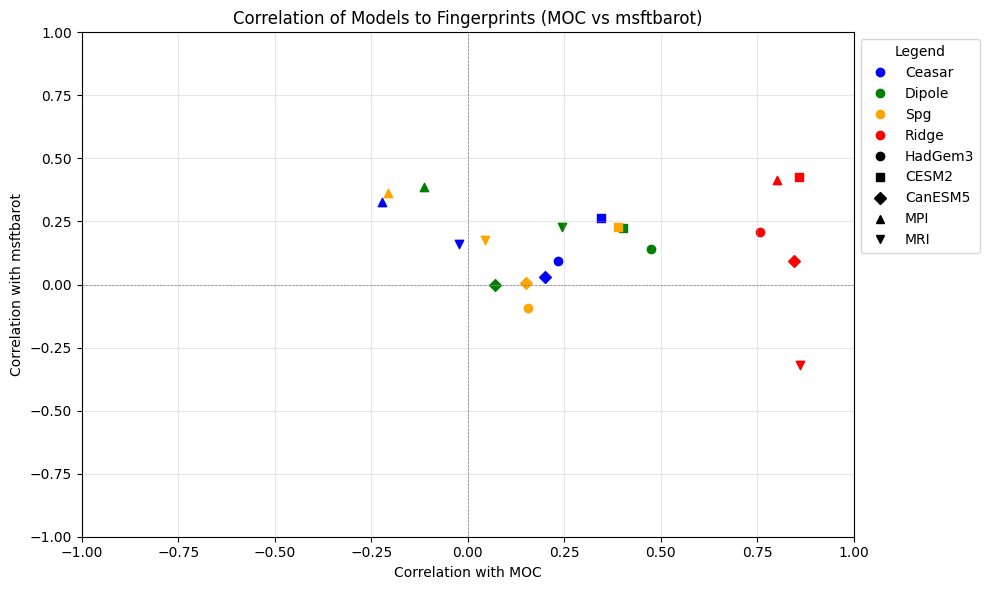

In [49]:
# List of fingerprints
fingerprints = ["ceasar", "dipole", "spg", "ridge"]

# Merge the two dataframes to align by model
merged_corrs = moc_corrs.set_index("model").join(msftbarot_corrs.set_index("model"), lsuffix="_moc", rsuffix="_msftbarot").reset_index()

# Integrating ridge correlation values for each model
for model in all_models:
    # Get the correlation values for Ridge MOC and MSFTBarot
    ridge_corr_moc = MOC_piControl_results[model]["Correlation"].iloc[:1].values[0]
    ridge_corr_msftbarot = moc_fingerprint_spg_corr[model]
    
    # Add these values to the merged_corrs dataframe for each model
    merged_corrs.loc[merged_corrs["model"] == model, "ridge_corr_moc"] = ridge_corr_moc
    merged_corrs.loc[merged_corrs["model"] == model, "ridge_corr_msftbarot"] = ridge_corr_msftbarot

# Colors for fingerprints
fingerprint_colors = {"ceasar": "blue", "dipole": "green", "spg": "orange", "ridge": "red"}

# Markers for models
model_markers = {"HadGem3": "o", "CESM2": "s", "CanESM5": "D", "MPI": "^", "MRI": "v"}

# Create the plot
plt.figure(figsize=(10, 6))

# Plot data for each fingerprint
for fp in fingerprints:
    for idx, row in merged_corrs.iterrows():
        x = row[f"{fp}_corr_moc"]  # MOC correlation
        y = row[f"{fp}_corr_msftbarot"]  # msftbarot correlation
        model = row["model"]  # Model name

        # Scatter plot with fingerprint color and model marker
        plt.scatter(
            x, y, 
            color=fingerprint_colors[fp], 
            marker=model_markers[model],
            label=f"{fp.capitalize()} ({model})" if idx == 0 else ""
        )

# Formatting the plot
plt.axhline(0, color='grey', linestyle='--', linewidth=0.5)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.5)
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.xlabel("Correlation with MOC")
plt.ylabel("Correlation with msftbarot")
plt.title("Correlation of Models to Fingerprints (MOC vs msftbarot)")

# Create a legend with distinct entries for fingerprints and models
handles = [
    plt.Line2D([], [], color=fingerprint_colors[fp], marker="o", linestyle="", label=fp.capitalize())
    for fp in fingerprints
] + [
    plt.Line2D([], [], color="black", marker=model_markers[model], linestyle="", label=model)
    for model in model_markers
]
plt.legend(handles=handles, title="Legend", loc="upper left", bbox_to_anchor=(1, 1))

plt.grid(alpha=0.3)
plt.tight_layout()

# Show the plot
plt.show()


In [96]:
moc_mean=CESM2_decedal_moc["mean_msftmz"]
time=np.arange(0,len(CESM2_decedal_moc), 1)
dipole=dipole_CESM2_df["tos"]
ceasar=ceasar_CESM2_df["tos"]
spg=spg_CESM2_df["tos"]

In [97]:
len(MOC_piControl_results["CESM2"]["Test_Predictions"].iloc[:1].values[0])

240

In [98]:
MOC_piControl_results=model_results
MOC_piControl_coefs=model_coefs

NameError: name 'model_results' is not defined

In [120]:
HadGem3_decedal_msftbarot=(HadGem3_decedal_msftbarot["mean_min_value"]-HadGem3_decedal_msftbarot["mean_min_value"].mean())
MPI_decedal_msftbarot=(MPI_decedal_msftbarot["mean_min_value"]-MPI_decedal_msftbarot["mean_min_value"].mean())
CESM2_decedal_msftbarot=(CESM2_decedal_msftbarot["mean_min_value"]-CESM2_decedal_msftbarot["mean_min_value"].mean())
CanESM5_decedal_msftbarot=(CanESM5_decedal_msftbarot["mean_min_value"]-CanESM5_decedal_msftbarot["mean_min_value"].mean())
MRI_decedal_msftbarot=(MRI_decedal_msftbarot["mean_min_value"]-MRI_decedal_msftbarot["mean_min_value"].mean())

In [121]:
# Define alpha values for testing 
alpha_values = np.logspace(3, 7, num=5)
all_models = ["HadGem3", "MPI", "CESM2", "CanESM5", "MRI"]

# Dictionaries to store results and coefficients for each model
model_results = {}
model_coefs = {}
ridge_models = {}  # Dictionary to store the Ridge models

# Loop through each model
for model in all_models:
    print(f"Processing model: {model}")
    
    # Dynamically access the features and msftbarot dataframes for the current model
    features_model_selected = globals()[f"features_{model}"].drop("Model", axis=1)
    msftbarot_model_selected = globals()[f"{model}_decedal_msftbarot"]
    
    # Split the data into training and testing sets
    train_features, test_features = train_test_split(features_model_selected, test_size=0.2, shuffle=False)
    train_msftbarot, test_msftbarot = train_test_split(msftbarot_model_selected, test_size=0.2, shuffle=False)
    
    
    # Initialize a dictionary for storing results of the current model
    results = {
        "Alpha": [],
        "Correlation": [],
        
        "Test_Predictions": [],  # Store test predictions
        "True_Values": []
    }
    
    # Create a DataFrame for coefficients, with alphas as index
    coef_df = pd.DataFrame(index=alpha_values, columns=train_features.columns)
    
    # Loop through each alpha value
    for i, alpha in enumerate(alpha_values):
        # Create and fit Ridge regression model
        ridge_model = Ridge(alpha=alpha)
        ridge_model.fit(train_features, train_msftbarot)  
        
        # Predict on the test set
        test_preds = ridge_model.predict(test_features)
        
        # Compute metrics
        #mse = mean_squared_error(test_moc, test_preds)
        correlation, _ = pearsonr(test_msftbarot, test_preds.flatten())  # Flatten test_msftbarot and predictions
        
        # Store results
        results["Alpha"].append(alpha)
        results["Correlation"].append(correlation)
       
        results["Test_Predictions"].append(test_preds)  # Store test predictions
        results["True_Values"].append(test_msftbarot.values.flatten())
        
        # Store coefficients for this alpha
        coef_df.loc[alpha] = ridge_model.coef_.flatten()
        
        # Save the Ridge model for the first alpha
        if i == 0:  # Save only for the first alpha
            ridge_models[model] = ridge_model
    
    # Convert results dictionary to DataFrame and save
    model_results[model] = pd.DataFrame(results)
    
    # Save the coefficient DataFrame for the current model
    model_coefs[model] = coef_df

Processing model: HadGem3
Processing model: MPI
Processing model: CESM2
Processing model: CanESM5
Processing model: MRI


In [122]:
Msftbarot_piControl_results=model_results
Msftbarot_piControl_coefs=model_coefs

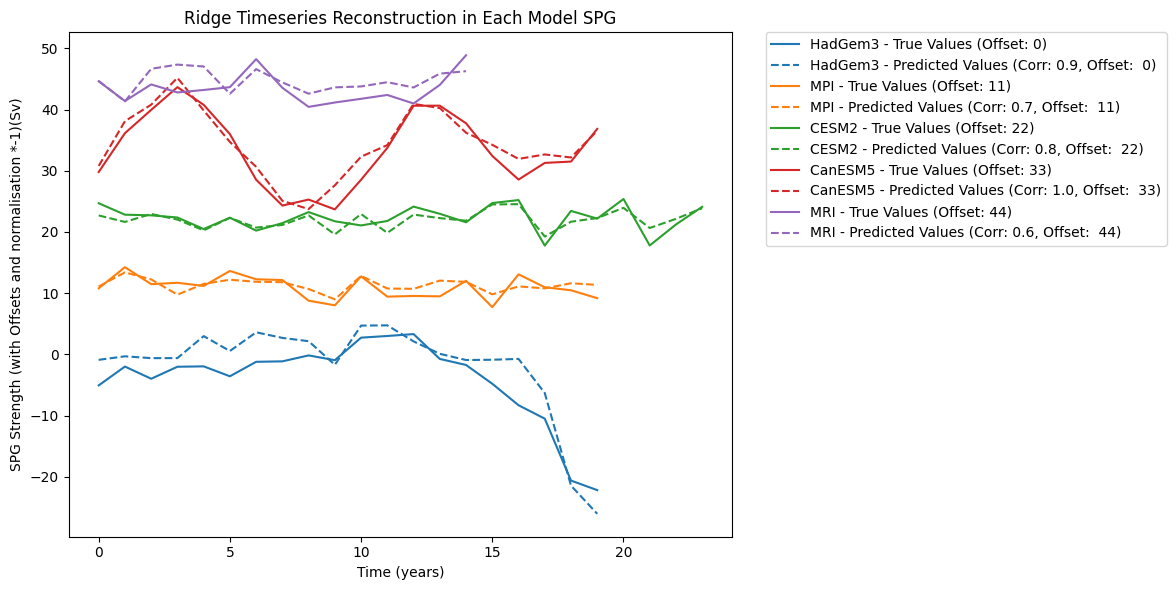

In [128]:
plt.figure(figsize=(12, 6))

offsets = np.arange(0, len(all_models))*11# Create distinct offsets for each model
for i, model in enumerate(all_models):
    results = Msftbarot_piControl_results[model]
    
    # Get predictions and true values for the first alpha
    preds = results.iloc[0]["Test_Predictions"]
    true_val = results.iloc[0]["True_Values"]
    corr = results.iloc[0]["Correlation"]
    time = np.arange(0, len(preds), 1)
    
    # Define consistent color for this model
    color = plt.cm.tab10(i)  # Use a colormap for distinct colors
    
    # Apply offset to the values
    offset = offsets[i]
    true_val_with_offset = true_val + offset
    preds_with_offset = preds + offset
    
    # Plot true values
    plt.plot(time, true_val_with_offset, label=f"{model} - True Values (Offset: {offset})", color=color)
    
    # Plot predictions as dashed line
    plt.plot(time, preds_with_offset, '--', label=f"{model} - Predicted Values (Corr: {corr:.1f}, Offset:  {offset})", color=color)

# Customize the plot
plt.title("Ridge Timeseries Reconstruction in Each Model SPG")
plt.xlabel("Time (years)")
plt.ylabel("SPG Strength (with Offsets and normalisation *-1)(Sv)")
plt.legend(loc="upper left", bbox_to_anchor=(1.05, 1), borderaxespad=0.)
plt.tight_layout()  # Adjust layout to fit everything
plt.show()